# Loan Approval Prediction

Predicts whether a loan application is **approved** or **rejected** from applicant details (income, loan amount, CIBIL score, assets and more). The notebook compares:

- a **Decision Tree**
- a **K-Nearest Neighbours** classifier, written from scratch and checked against scikit-learn's
- the effect of **PCA** on both
- the choice of *k* using **nested cross-validation**

**Dataset:** [Loan Approval Prediction Dataset](https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset) on Kaggle, 4,269 applications. A copy is included in `data/`.

## Import necessary libraries

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns


## Load the Dataset

In [2]:
# Load the dataset and display its size
DATA_PATH = "data/loan_approval_dataset.csv"
DATA_URL = "https://raw.githubusercontent.com/ziadelh/machine-learning-loan-approval/main/data/loan_approval_dataset.csv"
try:
    loan_data = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    loan_data = pd.read_csv(DATA_URL)
print("Size of the Dataset:", loan_data.shape)

Size of the Dataset: (4269, 13)


## Display Summary Statistics

In [3]:
# Display summary statistics for numerical columns
print("\nSummary Statistics:")
loan_data.describe()


Summary Statistics:


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


## Check for Missing Values and Clean Column Names and Unexpected Values

In [4]:
# Clean column names by stripping spaces
loan_data.rename(columns=lambda x: x.strip(), inplace=True)

# Check for missing values in the dataset
print("Checking if there are any missing values:")
print(loan_data.isnull().sum())

# Display unique values for categorical columns
print("\nUnique values in categorical columns:")
print("Unique values in 'education':", loan_data['education'].unique())
print("Unique values in 'self_employed':", loan_data['self_employed'].unique())
print("Unique values in 'loan_status':", loan_data['loan_status'].unique())


Checking if there are any missing values:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Unique values in categorical columns:
Unique values in 'education': [' Graduate' ' Not Graduate']
Unique values in 'self_employed': [' No' ' Yes']
Unique values in 'loan_status': [' Approved' ' Rejected']


## Analyze the Target Variable

In [5]:
# Display the class distribution for the target variable
target_column = 'loan_status'
class_distribution = loan_data[target_column].value_counts()
print("\nClass Distribution:\n", class_distribution)


Class Distribution:
 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


## Convert Categorical Columns to Binary Format

In [6]:
# Convert categorical columns to binary format
loan_data['education'] = loan_data['education'].str.strip().map({'Graduate': 1, 'Not Graduate': 0})
loan_data['self_employed'] = loan_data['self_employed'].str.strip().map({'Yes': 1, 'No': 0})
loan_data['loan_status'] = loan_data['loan_status'].str.strip().map({'Approved': 1, 'Rejected': 0})

# Display a preview of the converted columns
print("\nBinary Conversion Preview:")
loan_data[['education', 'self_employed', 'loan_status']].head()



Binary Conversion Preview:


,education,self_employed,loan_status
0,1,0,1
1,0,1,0
2,1,0,0
3,1,0,0
4,0,1,0


## Drop Unnecessary Columns and Verify the Cleaned Dataset

In [7]:
# Drop the 'loan_id' column 
loan_data = loan_data.drop(columns=['loan_id'], errors='ignore')

# Display the structure of the cleaned dataset
print("\nDataset after cleaning:")
loan_data.info()



Dataset after cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   no_of_dependents          4269 non-null   int64
 1   education                 4269 non-null   int64
 2   self_employed             4269 non-null   int64
 3   income_annum              4269 non-null   int64
 4   loan_amount               4269 non-null   int64
 5   loan_term                 4269 non-null   int64
 6   cibil_score               4269 non-null   int64
 7   residential_assets_value  4269 non-null   int64
 8   commercial_assets_value   4269 non-null   int64
 9   luxury_assets_value       4269 non-null   int64
 10  bank_asset_value          4269 non-null   int64
 11  loan_status               4269 non-null   int64
dtypes: int64(12)
memory usage: 400.3 KB


## Identify Continuous Numerical Features and Preprocess the Dataset

In [8]:
# Continuous numerical features
numerical_features = [
    'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
    'residential_assets_value', 'commercial_assets_value',
    'luxury_assets_value', 'bank_asset_value'
]

# Separate features and target variable
X = loan_data.drop(columns=['loan_status'])
y = loan_data['loan_status']

# Split the data into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()

# Standardize numerical features
scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])

## Decision Tree Classifier Function

In [9]:
# Define Decision Tree model
def train_decision_tree(X_train, X_test, y_train, y_test):
    tree = DecisionTreeClassifier(max_depth=5, random_state=42)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_test)
    return y_pred

## Decision Tree


--- Decision Tree ---
Decision Tree Accuracy Without PCA: 0.97

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.94      0.98      0.96       318
    Approved       0.99      0.96      0.97       536

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854



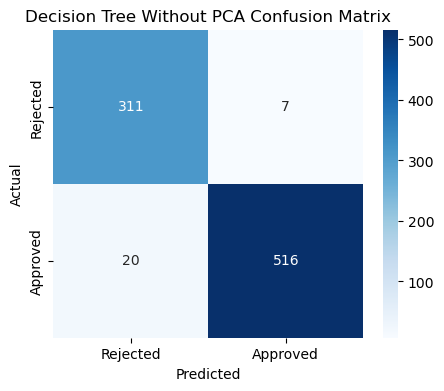

In [10]:
# Train and evaluate a Decision Tree model without PCA
print("\n--- Decision Tree ---")
dt_predictions = train_decision_tree(X_train, X_test, y_train, y_test)

# Calculate metrics
accuracy_dt = accuracy_score(y_test, dt_predictions)
print(f"Decision Tree Accuracy Without PCA: {accuracy_dt:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions, target_names=['Rejected', 'Approved']))

# Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, dt_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Rejected', 'Approved'], 
            yticklabels=['Rejected', 'Approved'])
plt.title("Decision Tree Without PCA Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## KNN Implementation From Scratch

In [11]:
# Define KNN Function (from scratch)
def knn_fromScratch(X_train, y_train, X_test, k_neighbors=5):
    def distance(x, y):
        return np.sqrt(np.sum((x - y) ** 2))
    predictions = []
    for test_point in X_test:
        distances = [
            distance(test_point, train_point) for train_point in X_train]
        # Get the nearest neighbors
        nearest_indices = np.argsort(distances)[:k_neighbors]
        nearest_labels = [y_train[idx] for idx in nearest_indices]
        # Get the most frequent label
        predictions.append(Counter(nearest_labels).most_common(1)[0][0])
    return np.array(predictions)


## KNN From Scratch


--- KNN From Scratch Evaluation (k=5) ---


KNN From Scratch Accuracy: 0.90

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.85      0.89      0.87       318
    Approved       0.93      0.91      0.92       536

    accuracy                           0.90       854
   macro avg       0.89      0.90      0.90       854
weighted avg       0.90      0.90      0.90       854



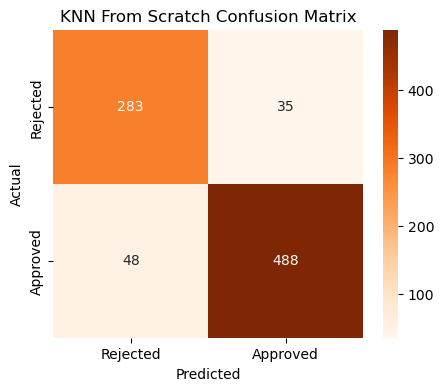

In [12]:
# KNN from scratch
print("\n--- KNN From Scratch Evaluation (k=5) ---")
knn_predictions = knn_fromScratch(X_train.to_numpy(), y_train.to_numpy(), X_test.to_numpy(), k_neighbors=5)

# Calculate metrics
print(f"KNN From Scratch Accuracy: {accuracy_score(y_test, knn_predictions):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, knn_predictions, target_names=['Rejected', 'Approved']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, knn_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Rejected', 'Approved'],
            yticklabels=['Rejected', 'Approved'])
plt.title("KNN From Scratch Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## KNN Built in Function

In [13]:
#Define Built in KNN Function
def knn_builtin(X_train, X_test, y_train, y_test, k_neighbors):
    knn = KNeighborsClassifier(n_neighbors=k_neighbors)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    return y_pred

## KNN From Scratch vs Built in KNN

In [14]:
print("\n--- KNN Comparison ---")

# predictions from built-in KNN 
knn_builtin_predictions = knn_builtin(X_train, X_test, y_train, y_test, k_neighbors=5)

# accuracy for both
accuracy_knn_scratch = accuracy_score(y_test, knn_predictions)
accuracy_knn_builtin = accuracy_score(y_test, knn_builtin_predictions)

# Accuracy Comparison
print(f"KNN From Scratch Accuracy: {accuracy_knn_scratch:.2f}")
print(f"Built-In KNN Accuracy: {accuracy_knn_builtin:.2f}")

# Classification Report Comparison
print("\n--- Classification Report Comparison ---")
print("KNN From Scratch Classification Report:")
print(classification_report(y_test, knn_predictions, target_names=['Rejected', 'Approved']))
print("\nBuilt In KNN Classification Report:")
print(classification_report(y_test, knn_builtin_predictions, target_names=['Rejected', 'Approved']))



--- KNN Comparison ---
KNN From Scratch Accuracy: 0.90
Built-In KNN Accuracy: 0.90

--- Classification Report Comparison ---
KNN From Scratch Classification Report:
              precision    recall  f1-score   support

    Rejected       0.85      0.89      0.87       318
    Approved       0.93      0.91      0.92       536

    accuracy                           0.90       854
   macro avg       0.89      0.90      0.90       854
weighted avg       0.90      0.90      0.90       854


Built In KNN Classification Report:
              precision    recall  f1-score   support

    Rejected       0.85      0.89      0.87       318
    Approved       0.93      0.91      0.92       536

    accuracy                           0.90       854
   macro avg       0.89      0.90      0.90       854
weighted avg       0.90      0.90      0.90       854



## PCA Function

In [15]:
# Define PCA
def apply_pca(X_train, X_test, numerical_features, n_components=5):
    pca = PCA(n_components=n_components)
    X_train_pca = pca.fit_transform(X_train[numerical_features])
    X_test_pca = pca.transform(X_test[numerical_features])

    # Combine PCA-transformed features with categorical features
    categorical_features = [
        col for col in X_train.columns if col not in numerical_features]
    
    X_train_combined = np.hstack(
        [X_train_pca, X_train[categorical_features].to_numpy()])
    
    X_test_combined = np.hstack(
        [X_test_pca, X_test[categorical_features].to_numpy()])

    return X_train_combined, X_test_combined

## Decision Tree With and Without PCA

In [16]:
# Compare Decision Tree With and Without PCA
print("\n--- Decision Tree Comparison With and Without PCA ---")

# Decision Tree Without PCA
print("\nDecision Tree Without PCA:")
dt_predictions_without_pca = train_decision_tree(X_train, X_test, y_train, y_test)
print("Accuracy Without PCA:", accuracy_score(y_test, dt_predictions_without_pca))
print("\nClassification Report Without PCA:")
print(classification_report(y_test, dt_predictions_without_pca, target_names=['Rejected', 'Approved']))

# Decision Tree With PCA
print("\nDecision Tree With PCA:")
X_train_combined, X_test_combined = apply_pca(X_train, X_test, numerical_features, n_components=5)
dt_predictions_pca = train_decision_tree(X_train_combined, X_test_combined, y_train, y_test)
print("Accuracy With PCA:", accuracy_score(y_test, dt_predictions_pca))
print("\nClassification Report With PCA:")
print(classification_report(y_test, dt_predictions_pca, target_names=['Rejected', 'Approved']))



--- Decision Tree Comparison With and Without PCA ---

Decision Tree Without PCA:
Accuracy Without PCA: 0.968384074941452

Classification Report Without PCA:
              precision    recall  f1-score   support

    Rejected       0.94      0.98      0.96       318
    Approved       0.99      0.96      0.97       536

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854


Decision Tree With PCA:
Accuracy With PCA: 0.9227166276346604

Classification Report With PCA:
              precision    recall  f1-score   support

    Rejected       0.89      0.90      0.90       318
    Approved       0.94      0.94      0.94       536

    accuracy                           0.92       854
   macro avg       0.92      0.92      0.92       854
weighted avg       0.92      0.92      0.92       854



## KNN With and Without PCA

In [17]:
print("\n--- KNN Comparison With and Without PCA ---")

# KNN Without PCA
print("\nKNN Without PCA...")
knn_predictions_no_pca = knn_builtin(X_train, X_test, y_train, y_test, k_neighbors=5)

accuracy_no_pca = accuracy_score(y_test, knn_predictions_no_pca)
print("KNN Without PCA Accuracy:", accuracy_no_pca)

# KNN With PCA
print("\nKNN With PCA...")
knn_predictions_pca = knn_builtin(
    X_train=X_train_combined,
    X_test=X_test_combined,
    y_train=y_train,
    y_test=y_test,
    k_neighbors=5)

accuracy_pca = accuracy_score(y_test, knn_predictions_pca)
print("KNN With PCA Accuracy:", accuracy_pca)

# Summary of Results
print("\n--- KNN Accuracy Comparison ---")
print(f"KNN Without PCA: {accuracy_no_pca:.2f}")
print(f"KNN With PCA: {accuracy_pca:.2f}")



--- KNN Comparison With and Without PCA ---

KNN Without PCA...
KNN Without PCA Accuracy: 0.9028103044496487

KNN With PCA...
KNN With PCA Accuracy: 0.8946135831381733

--- KNN Accuracy Comparison ---
KNN Without PCA: 0.90
KNN With PCA: 0.89


## Nested Cross Validation Function

In [18]:
# Define Nested Cross-Validation
def nested_cv(X, y, n_splits=5, k_range=range(1, 11)):
    param_grid = {'n_neighbors': list(k_range)}
    # Inner loop: GridSearchCV picks the best k on each outer training fold
    inner_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=n_splits, scoring='accuracy')
    # Outer loop: accuracy of the whole "pick k, then fit" procedure on unseen folds
    outer_scores = cross_val_score(inner_search, X, y, cv=n_splits, scoring='accuracy')

    # Final choice of k, using all of the training data
    inner_search.fit(X, y)
    best_k = inner_search.best_params_['n_neighbors']
    return best_k, outer_scores.mean()

## Nested Cross Validation on KNN

In [19]:
print("\n--- Nested CrossValidation for KNN ---")

# Run nested cross-validation
best_k, mean_accuracy = nested_cv(
    X=X_train.to_numpy(),
    y=y_train.to_numpy(),
    n_splits=5,
    k_range=range(1, 11))

print(f"Best k: {best_k}")
print(f"Nested CV accuracy estimate: {mean_accuracy:.3f}")

# Evaluate KNN with Default k=5
print("\nEvaluating KNN with Default k=5...")
knn_predictions_default = knn_builtin(X_train.to_numpy(), X_test.to_numpy(), y_train.to_numpy(), y_test.to_numpy(), k_neighbors=5)

accuracy_default = accuracy_score(y_test.to_numpy(), knn_predictions_default)
print(f"Accuracy with Default k: {accuracy_default:.2f}")

# Evaluate KNN with Best k
print("\nEvaluating KNN with Best k...")
knn_predictions_best_k = knn_builtin(X_train.to_numpy(), X_test.to_numpy(), y_train.to_numpy(), y_test.to_numpy(), k_neighbors=best_k)

accuracy_best_k = accuracy_score(y_test.to_numpy(), knn_predictions_best_k)
print(f"Accuracy with Best k: {accuracy_best_k:.2f}")

# Display Accuracy Comparison
print("\n--- Accuracy Comparison ---")
print(f"Accuracy with Default k: {accuracy_default:.2f}")
print(f"Accuracy with Best k (Nested CV): {accuracy_best_k:.2f}")



--- Nested CrossValidation for KNN ---


Best k: 10
Nested CV accuracy estimate: 0.913

Evaluating KNN with Default k=5...
Accuracy with Default k: 0.90

Evaluating KNN with Best k...
Accuracy with Best k: 0.90

--- Accuracy Comparison ---
Accuracy with Default k: 0.90
Accuracy with Best k (Nested CV): 0.90


## Final Evaluation for Decision Tree and KNN


--- Decision Tree Evaluation ---
Decision Tree Accuracy: 0.97

Decision Tree Classification Report:
              precision    recall  f1-score   support

    Rejected       0.94      0.98      0.96       318
    Approved       0.99      0.96      0.97       536

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854


--- KNN Evaluation (From Scratch) ---


KNN Accuracy: 0.90

KNN Classification Report:
              precision    recall  f1-score   support

    Rejected       0.85      0.89      0.87       318
    Approved       0.93      0.91      0.92       536

    accuracy                           0.90       854
   macro avg       0.89      0.90      0.90       854
weighted avg       0.90      0.90      0.90       854


--- Confusion Matrices ---


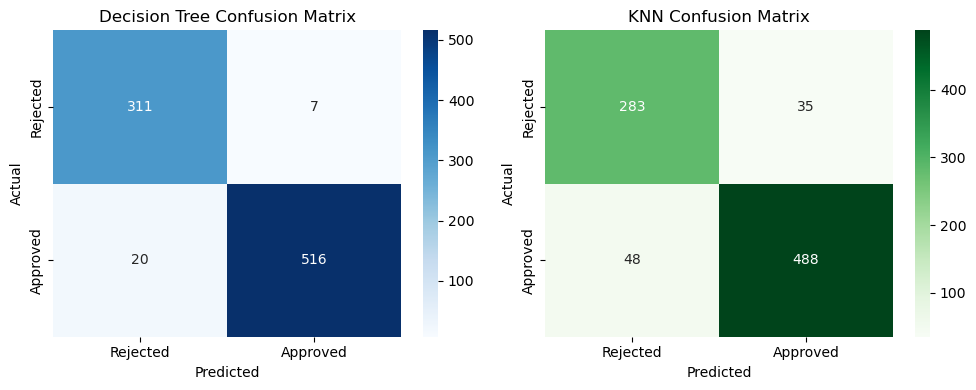


--- Summary of Results ---
Decision Tree Accuracy: 0.97
KNN (From Scratch) Accuracy: 0.90


In [20]:
print("\n--- Decision Tree Evaluation ---")
# Train and evaluate Decision Tree
decision_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
decision_tree.fit(X_train, y_train)
y_pred_dt = decision_tree.predict(X_test)

# Decision Tree Metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_accuracy:.2f}")
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt, target_names=['Rejected', 'Approved']))

print("\n--- KNN Evaluation (From Scratch) ---")
knn_predictions_scratch = knn_fromScratch(
    X_train=X_train.to_numpy(),
    y_train=y_train.to_numpy(),
    X_test=X_test.to_numpy(),
    k_neighbors=5
)
accuracy_knn_scratch = accuracy_score(y_test, knn_predictions_scratch)
print(f"KNN Accuracy: {accuracy_knn_scratch:.2f}")
print("\nKNN Classification Report:")
print(classification_report(y_test, knn_predictions_scratch, target_names=['Rejected', 'Approved']))

# Generating Confusion Matrices for Both Models
print("\n--- Confusion Matrices ---")
# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# KNN Confusion Matrix
cm_knn_scratch = confusion_matrix(y_test, knn_predictions_scratch)

# Plot Confusion Matrices
plt.figure(figsize=(10, 4))

# Decision Tree Confusion Matrix
plt.subplot(1, 2, 1)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Rejected', 'Approved'], 
            yticklabels=['Rejected', 'Approved'])
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# KNN Confusion Matrix
plt.subplot(1, 2, 2)
sns.heatmap(cm_knn_scratch, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Rejected', 'Approved'], 
            yticklabels=['Rejected', 'Approved'])
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# Print Summary of Results
print("\n--- Summary of Results ---")
print(f"Decision Tree Accuracy: {dt_accuracy:.2f}")
print(f"KNN (From Scratch) Accuracy: {accuracy_knn_scratch:.2f}")


## Summary of Results

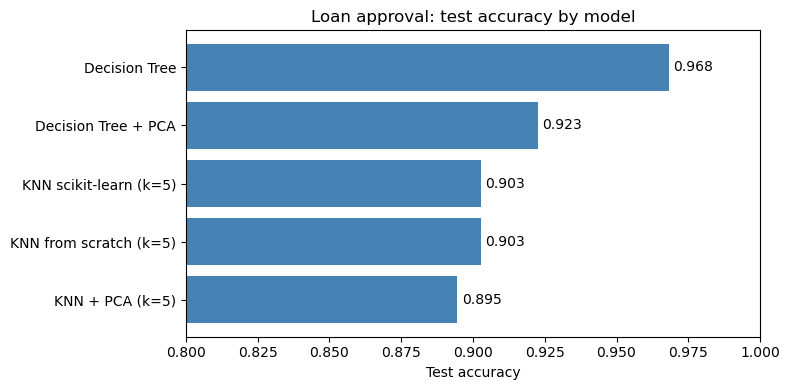

In [21]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "Decision Tree + PCA", "KNN from scratch (k=5)", "KNN scikit-learn (k=5)", "KNN + PCA (k=5)"],
    "Accuracy": [
        accuracy_score(y_test, dt_predictions_without_pca),
        accuracy_score(y_test, dt_predictions_pca),
        accuracy_knn_scratch,
        accuracy_knn_builtin,
        accuracy_pca,
    ],
}).sort_values("Accuracy")

plt.figure(figsize=(8, 4))
bars = plt.barh(results["Model"], results["Accuracy"], color="steelblue")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.xlim(0.8, 1.0)
plt.xlabel("Test accuracy")
plt.title("Loan approval: test accuracy by model")
plt.tight_layout()
plt.show()

## Conclusion

- The **Decision Tree** is the strongest model, at about **97%** accuracy on the held-out test set.
- My **KNN written from scratch** gives the same accuracy and classification report as scikit-learn's KNN (90.3% at k=5).
- **PCA lowered accuracy** for both models (Decision Tree 96.8% to 92.3%, KNN 90.3% to 89.5%), so here the dimensionality reduction costs accuracy instead of helping.
- **Nested cross-validation** picks k=10 for KNN with an estimated accuracy of 91.3%, only a small gain over k=5.